In [2]:
import os
import cv2
import numpy as np
import seaborn as sns
from tqdm import tqdm

import torch
import torchvision

from torchsummary import summary
from torch.nn import functional as F

from PIL import Image
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import label_binarize

In [3]:
IMG_DIR = "data/prep/S_299_R_1_C_True"  # "The directory where the images are stored"
BATCH_SIZE = 32  # The batch size for the dataloader
NUM_WORKERS = os.cpu_count() - 2  # The number of workers for the dataloader
USE_AMP = True  # Use Automatic Mixed Precision (False for non cuda cards)
EPOCHS = 5  # The number of epochs to train the model
BINARY = True  # Whether to use binary classification or not

In [4]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
# Check if the device is a cuda device
print(device)

cuda:0


In [5]:
def get_folder_structure(base="data"):
    """
    Returns the folder structure of the data folder
    """
    return [x[0] for x in os.walk(base)]


get_folder_structure()

['data',
 'data/prep',
 'data/prep/S_224_R_1_C_False',
 'data/prep/S_224_R_1_C_False/test',
 'data/prep/S_224_R_1_C_False/test/0',
 'data/prep/S_224_R_1_C_False/test/1',
 'data/prep/S_224_R_1_C_False/test/2',
 'data/prep/S_224_R_1_C_False/test/3',
 'data/prep/S_224_R_1_C_False/test/4',
 'data/prep/S_224_R_1_C_False/train',
 'data/prep/S_224_R_1_C_False/train/0',
 'data/prep/S_224_R_1_C_False/train/1',
 'data/prep/S_224_R_1_C_False/train/2',
 'data/prep/S_224_R_1_C_False/train/3',
 'data/prep/S_224_R_1_C_False/train/4',
 'data/prep/S_224_R_1_C_True',
 'data/prep/S_224_R_1_C_True/test',
 'data/prep/S_224_R_1_C_True/test/0',
 'data/prep/S_224_R_1_C_True/test/1',
 'data/prep/S_224_R_1_C_True/test/2',
 'data/prep/S_224_R_1_C_True/test/3',
 'data/prep/S_224_R_1_C_True/test/4',
 'data/prep/S_224_R_1_C_True/train',
 'data/prep/S_224_R_1_C_True/train/0',
 'data/prep/S_224_R_1_C_True/train/1',
 'data/prep/S_224_R_1_C_True/train/2',
 'data/prep/S_224_R_1_C_True/train/3',
 'data/prep/S_224_R_1_C_T

In [6]:
class CImageFolderDataset(torch.utils.data.Dataset):
    """
    Custom dataset class for the image folder, it allows the individual classes to be loaded
    """

    def __init__(self, root_dir, classes, transform=None):
        self.root_dir = root_dir
        self.classes = classes
        self.transform = transform
        self.image_paths = []
        self.labels = []

        for class_idx, class_name in enumerate(classes):
            class_dir = os.path.join(root_dir, class_name)
            if os.path.isdir(class_dir):
                for image_name in os.listdir(class_dir):
                    image_path = os.path.join(class_dir, image_name)
                    self.image_paths.append(image_path)
                    self.labels.append(class_idx)

        self.class_to_idx = {cls: i for i, cls in enumerate(classes)}

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
if BINARY:
    # If binary classification is enabled, only use classes 0 and 4
    classes = ["0", "4"]
else:
    classes = ["0", "1", "2", "3", "4"]

# Load the training data from the data folder
trainset = CImageFolderDataset(
    root_dir=os.path.join(IMG_DIR, "train/"),
    classes=classes,
    transform=torchvision.transforms.ToTensor(),
)
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,  # Pin the memory for faster data loading
)
testset = CImageFolderDataset(
    root_dir=os.path.join(IMG_DIR, "test/"),
    classes=classes,
    transform=torchvision.transforms.ToTensor(),
)
testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

Label : 0


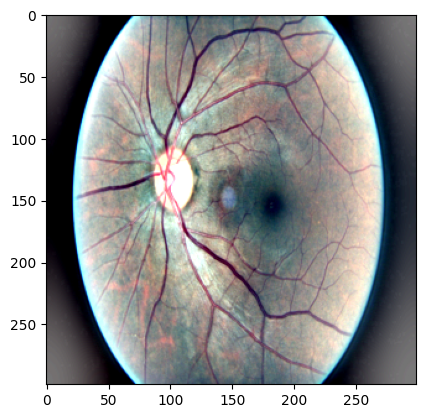

In [8]:
def display_img(img, label):
    print(f"Label : {trainset.classes[label]}")
    img_valid_range = np.clip(img.numpy().transpose((1, 2, 0)), 0, 1)
    plt.imshow(img_valid_range)


# display the first image in the dataset
display_img(*trainset[0])

In [9]:
num_classes = len(trainset.classes)

# load the model
model = torchvision.models.inception_v3(
    weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1
)

# Modify the final layer for our classification task
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)  # For Inception V3
# model.classifier[6] = torch.nn.Linear(model.classifier[6].in_features, num_classes) # For ResNet

# Move model to device
model = model.to(device)
# model = torch.compile(model) # This is actually slower than not compiling the model

In [10]:
# Check the model summary
summary(model, (3, 299, 299), device=device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 149, 149]             864
       BatchNorm2d-2         [-1, 32, 149, 149]              64
       BasicConv2d-3         [-1, 32, 149, 149]               0
            Conv2d-4         [-1, 32, 147, 147]           9,216
       BatchNorm2d-5         [-1, 32, 147, 147]              64
       BasicConv2d-6         [-1, 32, 147, 147]               0
            Conv2d-7         [-1, 64, 147, 147]          18,432
       BatchNorm2d-8         [-1, 64, 147, 147]             128
       BasicConv2d-9         [-1, 64, 147, 147]               0
        MaxPool2d-10           [-1, 64, 73, 73]               0
           Conv2d-11           [-1, 80, 73, 73]           5,120
      BatchNorm2d-12           [-1, 80, 73, 73]             160
      BasicConv2d-13           [-1, 80, 73, 73]               0
           Conv2d-14          [-1, 192,

In [11]:
criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(), lr=1e-4, weight_decay=1e-5
)  # This is for Inception V3

# optimizer = torch.optim.Adam(
#     model.classifier[6].parameters(), lr=1e-4, weight_decay=1e-5
# )  #This is for ResNet

lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5
)  # Reduce the learning rate on plateau

# GradScaler for Automatic Mixed Precision (CUDA only)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

In [12]:
torch.set_num_threads(NUM_WORKERS)  # Use NUM_WORKERS for data loading
torch.backends.cudnn.benchmark = True  # Enable cuDNN benchmarking for faster training

In [13]:
def train_model(model, criterion, optimizer, num_epochs=10):
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in tqdm(trainloader):
            inputs, labels = inputs.to(device), labels.to(device)

            # Zero the parameter gradients (this is an optimization vs zero_grad)
            for param in model.parameters():
                param.grad = None

            # Automatic Mixed Precision (CUDA only)
            with torch.autocast(
                device_type="cuda", dtype=torch.float16, enabled=USE_AMP
            ):
                outputs, _ = model(inputs)
                loss = criterion(outputs, labels)

            # Backward and optimize
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item() * inputs.size(0)
        epoch_loss = running_loss / len(trainloader.dataset)
        print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}")
        # Validation loop
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():  # No gradients needed for validation
            for inputs, labels in testloader:
                inputs, labels = (
                    inputs.to(device),
                    labels.to(device),
                )
                with torch.autocast(
                    device_type="cuda", dtype=torch.float16, enabled=USE_AMP
                ):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss = val_loss / len(testloader.dataset)
        accuracy = 100 * correct / total
        print(f"Validation Loss: {val_loss:.4f}, Accuracy: {accuracy:.2f}%")
        lr_scheduler.step(val_loss)  # Adjust learning rate based on validation loss
        current_lr = optimizer.param_groups[0]["lr"]
        print(f"Current Learning Rate: {current_lr:.6f}")

In [14]:
train_model(model, criterion, optimizer, num_epochs=EPOCHS)

  0%|          | 0/206 [00:00<?, ?it/s]

100%|██████████| 206/206 [00:50<00:00,  4.07it/s]

Epoch 1/5, Loss: 0.5664


Validation Loss: 0.4562, Accuracy: 85.42%
Current Learning Rate: 0.000100


100%|██████████| 206/206 [00:37<00:00,  5.53it/s]

Epoch 2/5, Loss: 0.4453


... (6 outputs left out)

Validation Loss: 0.3430, Accuracy: 86.79%
Current Learning Rate: 0.000100


100%|██████████| 206/206 [00:39<00:00,  5.26it/s]

Epoch 5/5, Loss: 0.3575


Validation Loss: 0.3325, Accuracy: 86.88%
Current Learning Rate: 0.000100


In [15]:
# Save the trained model to disk
model_save_path = os.path.join("models", "inceptionv3_binary_classifier.pth")

os.makedirs("models", exist_ok=True)

# Save the model state dictionary
torch.save(model.state_dict(), model_save_path)

# Save the full model
torch.save(model, os.path.join("models", "vggB_full_model.pt"))

In [16]:
# Get the model accuracy
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Precisión en el conjunto de prueba: {100 * correct / total:.2f}%")

Precisión en el conjunto de prueba: 87.14%


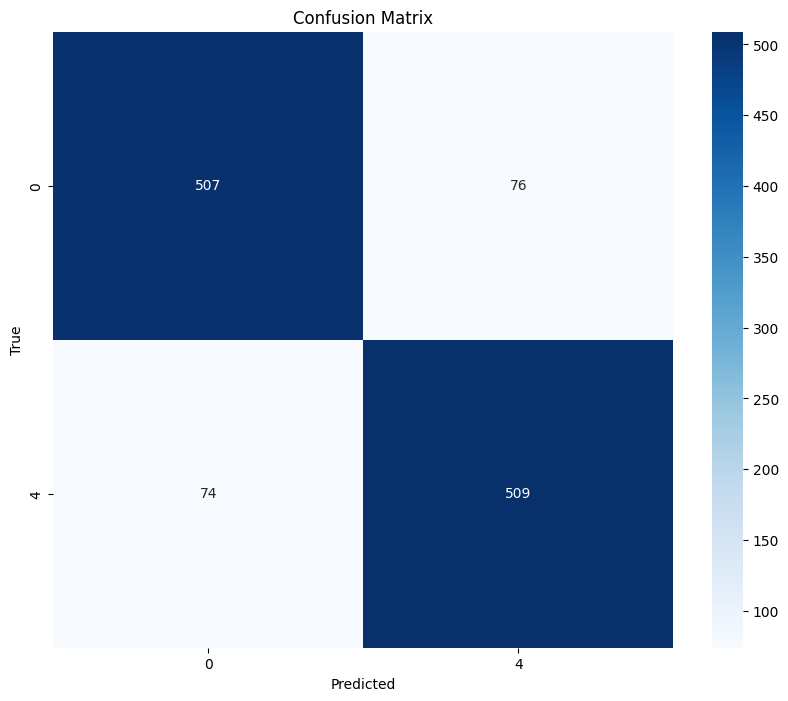

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87       583
           4       0.87      0.87      0.87       583

    accuracy                           0.87      1166
   macro avg       0.87      0.87      0.87      1166
weighted avg       0.87      0.87      0.87      1166

AUC-ROC: 0.9391124749550589


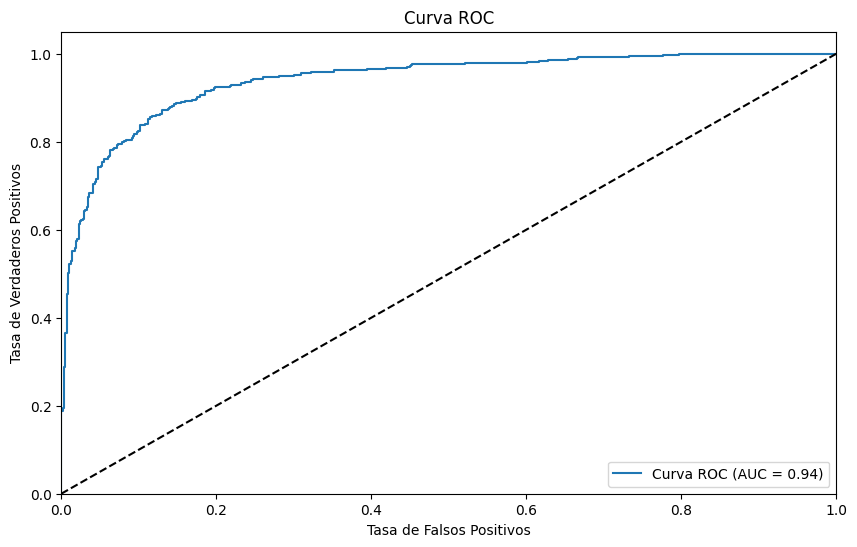

In [17]:
model.eval()
all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get the probabilities of the prediction
        probabilities = torch.softmax(outputs, dim=1)
        all_probabilities.extend(probabilities.cpu().numpy())

        # Get the predicted class
        _, predicted = torch.max(outputs.data, 1)
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Plot the confusion matrix
cm = confusion_matrix(all_labels, all_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=trainset.classes,
    yticklabels=trainset.classes,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Print the classification report
print("Classification Report:")
print(classification_report(all_labels, all_predictions, target_names=trainset.classes))


all_probabilities = np.array(all_probabilities)
all_labels = np.array(all_labels)


if BINARY:
    roc_auc = roc_auc_score(
        all_labels, all_probabilities[:, 1]
    )  # Using the probabilities of the positive class
    print(f"AUC-ROC: {roc_auc}")
    fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities[:, 1])
else:
    # For multi-class classification, we need to binarize the labels
    all_labels_bin = label_binarize(all_labels, classes=np.arange(num_classes))

    # Calculate the ROC-AUC score for each class
    roc_auc = roc_auc_score(all_labels_bin, all_probabilities, average="macro")
    print(f"AUC-ROC: {roc_auc}")
    fpr, tpr, _ = roc_curve(all_labels_bin.ravel(), all_probabilities.ravel())


# Plot the ROC curve
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Curva ROC (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], "k--")  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.show()

## CAM-ANALYSIS

In [18]:
# Load a sample image
img_path = "data/prep/S_299_R_1_C_True/test/4/image_260.png"
image = cv2.imread(img_path)
orig_image = image.copy()

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
height, width, _ = image.shape

In [19]:
model.eval()
activation = {}


# Store the feature maps at the final convolutional layer
def getActivation(name):
    def hook(model, input, output):
        activation[name] = output.detach()

    return hook


# For InceptionV3 we use Mixed_7c as the final convolutional layer
model.Mixed_7c.register_forward_hook(getActivation("final_conv"))

In [20]:
# Transform the image to a tensor and move to device
transform = torchvision.transforms.ToTensor()
image_tensor = transform(image)
image_tensor = image_tensor.unsqueeze(0).to(device)

# forward pass through model
outputs = model(image_tensor)

# get the idx of predicted class
class_idx = F.softmax(outputs).argmax().item()
print(class_idx)  # 0 is Healthy, 4 is Severe

1


/tmp/ipykernel_1796/2284276874.py:10: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  class_idx = F.softmax(outputs).argmax().item()


In [21]:
conv_features = activation["final_conv"]

# Fetch the learned weights at the final layer and move to CPU
weight_fc = model.fc.weight.detach().cpu().numpy()

In [22]:
def calculate_cam(feature_conv, weight_fc, class_idx):
    # generate the class activation maps upsampling to 299x299
    size_upsample = (299, 299)

    bz, nc, h, w = feature_conv.shape

    # Get the weights for the target class and compute the dot product with flattened features
    cam = weight_fc[class_idx].dot(feature_conv.reshape((nc, h * w)).cpu().numpy())
    cam = cam.reshape(h, w)
    cam = cam - np.min(cam)
    cam_img = cam / np.max(cam)
    cam_img = np.uint8(255 * cam_img)
    output_cam = cv2.resize(cam_img, size_upsample)

    return output_cam


class_activation_map = calculate_cam(conv_features, weight_fc, class_idx)

In [23]:
def visualize_cam(class_activation_map, width, height, orig_image):
    # Create the heatmap using the class activation map
    heatmap = cv2.applyColorMap(
        cv2.resize(class_activation_map, (width, height)), cv2.COLORMAP_JET
    )
    orig_image_rgb = cv2.cvtColor(orig_image, cv2.COLOR_BGR2RGB)

    # Interactive visualization function
    def show_blend(alpha=0.5):
        # Here we blend the two images based on alpha value from slider
        blended = cv2.addWeighted(orig_image, 1 - alpha, heatmap, alpha, 0)
        blended_rgb = cv2.cvtColor(blended.astype(np.uint8), cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        plt.imshow(orig_image_rgb)
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(blended_rgb)
        plt.title(f"Class Activation Map (Alpha: {alpha:.2f})")
        plt.axis("off")
        plt.tight_layout()
        plt.show()

    # Create the interactive slider widget
    interact(
        show_blend,
        alpha=FloatSlider(
            min=0,
            max=1.0,
            step=0.05,
            value=0.5,
            description="Blend:",
            style={"description_width": "initial"},
        ),
    )


visualize_cam(class_activation_map, width, height, orig_image)

interactive(children=(FloatSlider(value=0.5, description='Blend:', max=1.0, step=0.05, style=SliderStyle(descr…